# Day 1 - Data foundations practical tasks
***

These tasks cover data preparation, visualization and feature engineering topics.

## Explore the datasets and answer the questions below.
#### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu 
* when you are making plots, please add labels to the axes

For this task you will use red wine dataset

In [35]:
import pandas as pd
import numpy as np
wine_data = pd.read_csv('winequality-red.csv', sep = ';')
wine_data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [36]:
wine_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [37]:
wine_data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [38]:
wine_data.isnull().values.sum()

np.int64(0)

### 1. `quality` attribute in the DataFrame has a score from 0 to 10. How many observations (rows) belong to each score level? 

In [39]:
wine_data['quality'].value_counts().sort_index()

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

### 2. Make a bar plot, where we can see distribution of the samples against quality attributes.

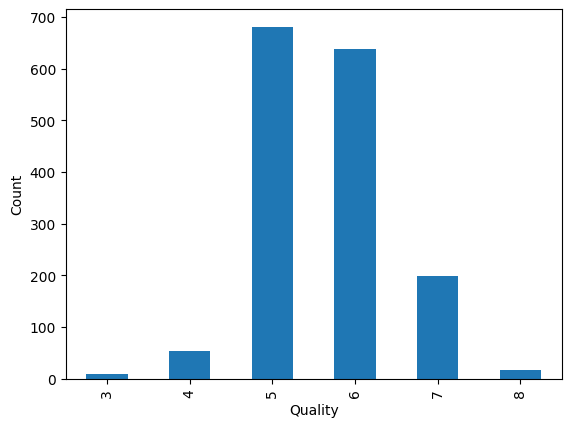

In [40]:
import matplotlib.pyplot as mat

wine_data['quality'].value_counts().sort_index().plot(kind='bar')
mat.xlabel('Quality')
mat.ylabel('Count')
mat.show()

### 3. What is the average value of each feature (column) in each `quality` score level? 

In [41]:
wine_data.groupby('quality').mean().round(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,8.36,0.88,0.17,2.64,0.12,11.00,24.90,1.0,3.40,0.57,9.96
4,7.78,0.69,0.17,2.69,0.09,12.26,36.25,1.0,3.38,0.60,10.27
5,8.17,0.58,0.24,2.53,0.09,16.98,56.51,1.0,3.30,0.62,9.90
6,8.35,0.50,0.27,2.48,0.08,15.71,40.87,1.0,3.32,0.68,10.63
7,8.87,0.40,0.38,2.72,0.08,14.05,35.02,1.0,3.29,0.74,11.47
8,8.57,0.42,0.39,2.58,0.07,13.28,33.44,1.0,3.27,0.77,12.09


### 4. What is the median value of each feature (column) in each `quality` score level? 

In [42]:
wine_data.groupby('quality').median().round(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,7.50,0.84,0.04,2.1,0.09,6.0,15.0,1.00,3.39,0.55,9.93
4,7.50,0.67,0.09,2.1,0.08,11.0,26.0,1.00,3.37,0.56,10.00
5,7.80,0.58,0.23,2.2,0.08,15.0,47.0,1.00,3.30,0.58,9.70
6,7.90,0.49,0.26,2.2,0.08,14.0,35.0,1.00,3.32,0.64,10.50
7,8.80,0.37,0.40,2.3,0.07,11.0,27.0,1.00,3.28,0.74,11.50
8,8.25,0.37,0.42,2.1,0.07,7.5,21.5,0.99,3.23,0.74,12.15


### 5. We can notice that for some features raw values differ significantly. Scale the data (except quality column) using Min-Max Scaling manually (create formula yourself). Then use built-in Min-Max Scaling function to validate results (display the resulting data frames separately).
#### Hint: you can use `pd.DataFrame(<your data>)` to display the result of the built-in function in a nicer way.

In [43]:
wine_features = wine_data.drop(columns='quality')
scaled_manual = (wine_features - wine_features.min()) / (wine_features.max() - wine_features.min())
scaled_manual.round(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,0.25,0.40,0.00,0.07,0.11,0.14,0.10,0.57,0.61,0.14,0.15
1,0.28,0.52,0.00,0.12,0.14,0.34,0.22,0.49,0.36,0.21,0.22
2,0.28,0.44,0.04,0.10,0.13,0.20,0.17,0.51,0.41,0.19,0.22
3,0.58,0.11,0.56,0.07,0.11,0.23,0.19,0.58,0.33,0.15,0.22
4,0.25,0.40,0.00,0.07,0.11,0.14,0.10,0.57,0.61,0.14,0.15
...,...,...,...,...,...,...,...,...,...,...,...
1594,0.14,0.33,0.08,0.08,0.13,0.44,0.13,0.35,0.56,0.15,0.32
1595,0.12,0.29,0.10,0.09,0.08,0.54,0.16,0.37,0.61,0.26,0.43
1596,0.15,0.27,0.13,0.10,0.11,0.39,0.12,0.42,0.54,0.25,0.40
1597,0.12,0.36,0.12,0.08,0.11,0.44,0.13,0.40,0.65,0.23,0.28


In [44]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

wine_features = wine_data.drop(columns='quality')
scaler = MinMaxScaler()
scaled_builtin = pd.DataFrame(scaler.fit_transform(wine_features), columns=wine_features.columns)
scaled_builtin.round(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,0.25,0.40,0.00,0.07,0.11,0.14,0.10,0.57,0.61,0.14,0.15
1,0.28,0.52,0.00,0.12,0.14,0.34,0.22,0.49,0.36,0.21,0.22
2,0.28,0.44,0.04,0.10,0.13,0.20,0.17,0.51,0.41,0.19,0.22
3,0.58,0.11,0.56,0.07,0.11,0.23,0.19,0.58,0.33,0.15,0.22
4,0.25,0.40,0.00,0.07,0.11,0.14,0.10,0.57,0.61,0.14,0.15
...,...,...,...,...,...,...,...,...,...,...,...
1594,0.14,0.33,0.08,0.08,0.13,0.44,0.13,0.35,0.56,0.15,0.32
1595,0.12,0.29,0.10,0.09,0.08,0.54,0.16,0.37,0.61,0.26,0.43
1596,0.15,0.27,0.13,0.10,0.11,0.39,0.12,0.42,0.54,0.25,0.40
1597,0.12,0.36,0.12,0.08,0.11,0.44,0.13,0.40,0.65,0.23,0.28


### 6. Create correlation matrix between all variables.

In [45]:
wine_data.corr().round(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.00,-0.26,0.67,0.11,0.09,-0.15,-0.11,0.67,-0.68,0.18,-0.06,0.12
volatile acidity,-0.26,1.00,-0.55,0.00,0.06,-0.01,0.08,0.02,0.23,-0.26,-0.20,-0.39
citric acid,0.67,-0.55,1.00,0.14,0.20,-0.06,0.04,0.36,-0.54,0.31,0.11,0.23
residual sugar,0.11,0.00,0.14,1.00,0.06,0.19,0.20,0.36,-0.09,0.01,0.04,0.01
chlorides,0.09,0.06,0.20,0.06,1.00,0.01,0.05,0.20,-0.27,0.37,-0.22,-0.13
free sulfur dioxide,-0.15,-0.01,-0.06,0.19,0.01,1.00,0.67,-0.02,0.07,0.05,-0.07,-0.05
total sulfur dioxide,-0.11,0.08,0.04,0.20,0.05,0.67,1.00,0.07,-0.07,0.04,-0.21,-0.19
density,0.67,0.02,0.36,0.36,0.20,-0.02,0.07,1.00,-0.34,0.15,-0.50,-0.17
pH,-0.68,0.23,-0.54,-0.09,-0.27,0.07,-0.07,-0.34,1.00,-0.20,0.21,-0.06
sulphates,0.18,-0.26,0.31,0.01,0.37,0.05,0.04,0.15,-0.20,1.00,0.09,0.25


### 7. Plot heatmap to see correlations.

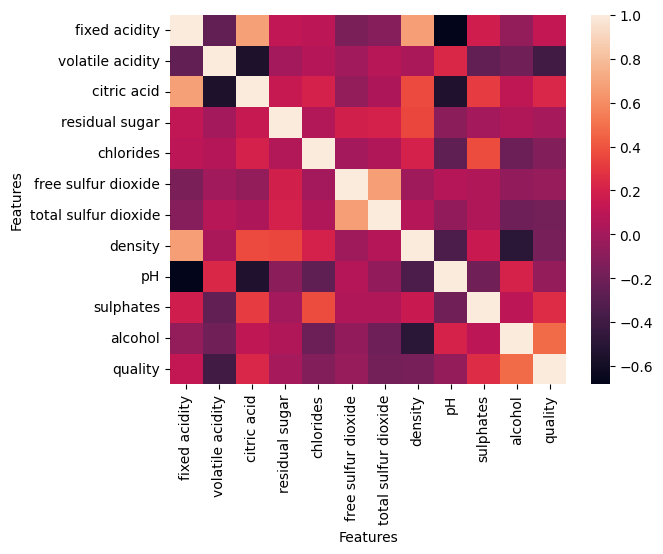

In [46]:
import seaborn as sea
import matplotlib.pyplot as mat

sea.heatmap(wine_data.corr())
mat.xlabel('Features')
mat.ylabel('Features')
mat.show()

### 8. Identify the first and last 10% of data outliers in `alcohol`

In [47]:
import pandas as pd

alcohol = wine_data['alcohol']
low = alcohol.quantile(0.1)
high = alcohol.quantile(0.9)
print(round(low, 2), round(high, 2))
low_outliers = pd.DataFrame(alcohol[alcohol < low])
high_outliers = pd.DataFrame(alcohol[alcohol > high])

display(low_outliers.round(2))
display(high_outliers.round(2))

9.3 12.0


,alcohol
10,9.20
13,9.10
14,9.20
15,9.20
18,9.00
...,...
1515,9.25
1521,9.05
1533,9.00
1568,9.20


,alcohol
45,13.1
95,12.9
131,13.0
132,13.0
142,14.0
...,...
1490,12.4
1547,12.1
1570,12.4
1573,12.5


### 9. Plot boxplots for all columns (except quality), use figure size 15x6. You can use both original and scaled data for this task. Try to interpret the data for one feature of your choice and write your observations.

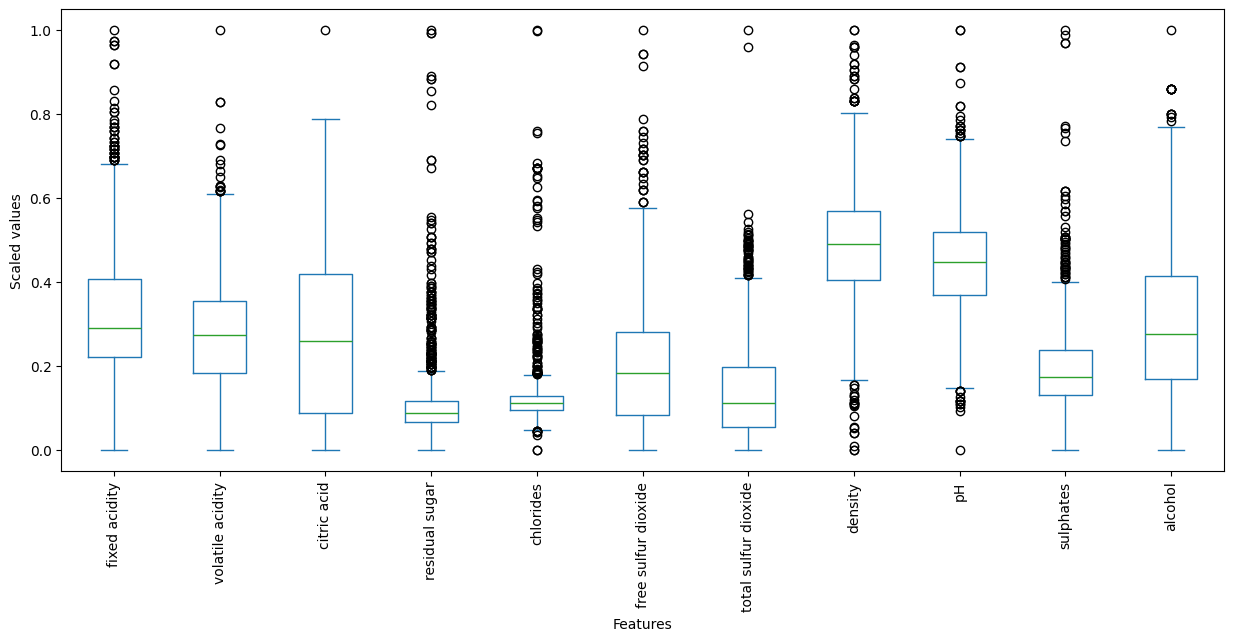

In [48]:
import matplotlib.pyplot as mat

wine_features = wine_data.drop(columns='quality')
scaled_data = (wine_features - wine_features.min()) / (wine_features.max() - wine_features.min())
scaled_data.plot.box(figsize=(15, 6), rot=90)
mat.xlabel('Features')
mat.ylabel('Scaled values')
mat.show()

Most alcohol values are in the lower part of the scaled range, with some higher outliers.

### 10. Plot boxplot of Ph for each quality type.

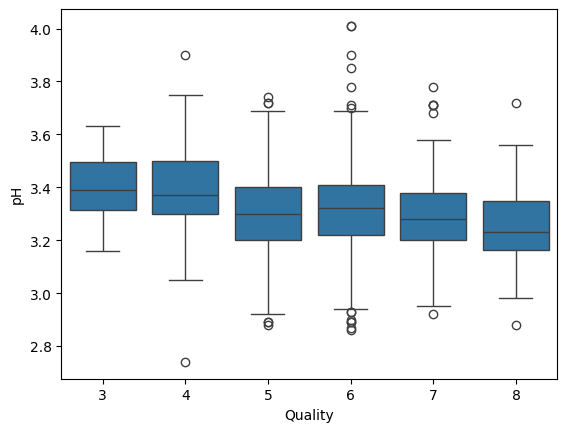

In [49]:
import seaborn as sea
import matplotlib.pyplot as mat

sea.boxplot(data=wine_data, x='quality', y='pH')
mat.xlabel('Quality')
mat.ylabel('pH')
mat.show()

### 11. Plot scatter plot for `quality` and column with strongest correlation to it. Does alcohol influence the quality of the wine?

alcohol 0.48


<Axes: xlabel='alcohol', ylabel='quality'>

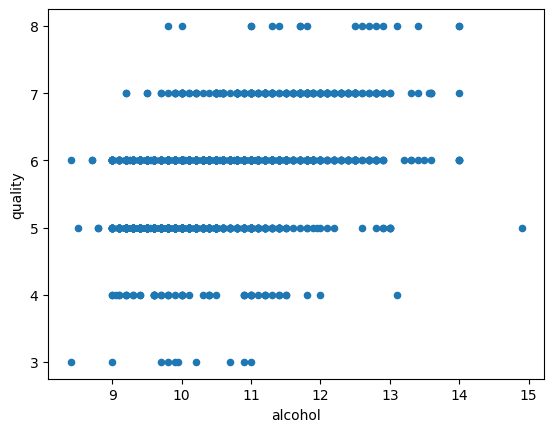

In [50]:
correlation = wine_data.corr()['quality'].drop('quality')
strongest = correlation.abs().idxmax()

print(strongest, round(correlation[strongest], 2))

wine_data.plot.scatter(x=strongest, y='quality')

Alcohol has the strongest correlation with quality (0.48). Wines with higher alcohol content tend to have higher quality scores, but correlation does not prove causation.

### 12. Plot scatter plot for any two columns and color it by `quality` number. Add color legend and write your observations.

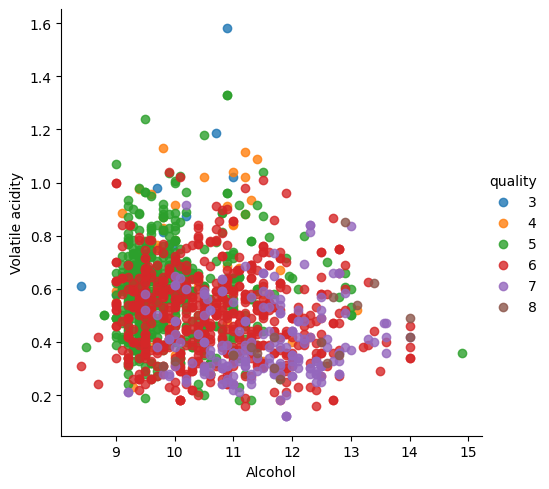

In [51]:
import seaborn as sea

plot = sea.lmplot(data=wine_data, x='alcohol', y='volatile acidity', hue='quality', fit_reg=False)
plot.set_axis_labels('Alcohol', 'Volatile acidity')

Higher quality wines tend to have more alcohol and lower volatile acidity, but the groups overlap.

### 13. Create X, y for independent variables (all except `quality`) and target variable `quality`, perform k-fold k=3 split on them and calculate and print out the length of training set and testing set for each fold

In [52]:
from sklearn.model_selection import KFold

X = wine_data.drop(columns='quality')
y = wine_data['quality']
folds = KFold(n_splits=3, shuffle=True, random_state=42)

In [53]:
for train, test in folds.split(X):
    X_train = X.iloc[train]
    X_test = X.iloc[test]
    
    print('Train:', len(X_train), 'Test:', len(X_test))

Train: 1066 Test: 533
Train: 1066 Test: 533
Train: 1066 Test: 533


### 14. Create two new features:
- Sulfur dioxide ration (`free sulfur dioxide` / `total sulfur dioxide`)
- Total acidity (`fixed acidity` + `volatile acidity` + `citric acid`)

In [54]:
wine_new = wine_data.copy()
wine_new['sulfur dioxide ratio'] = wine_new['free sulfur dioxide'] / wine_new['total sulfur dioxide']
wine_new['total acidity'] = wine_new['fixed acidity'] + wine_new['volatile acidity'] + wine_new['citric acid']
wine_new.head().round(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,sulfur dioxide ratio,total acidity
0,7.4,0.70,0.00,1.9,0.08,11.0,34.0,1.0,3.51,0.56,9.4,5,0.32,8.10
1,7.8,0.88,0.00,2.6,0.10,25.0,67.0,1.0,3.20,0.68,9.8,5,0.37,8.68
2,7.8,0.76,0.04,2.3,0.09,15.0,54.0,1.0,3.26,0.65,9.8,5,0.28,8.60
3,11.2,0.28,0.56,1.9,0.08,17.0,60.0,1.0,3.16,0.58,9.8,6,0.28,12.04
4,7.4,0.70,0.00,1.9,0.08,11.0,34.0,1.0,3.51,0.56,9.4,5,0.32,8.10


### 15. Create a sample dataset with dates for a whole week. Extract day of the week with `dayofweek` function (0=Monday, 6=Sunday). Additionally flag weekends by creating another new `is_weekend` feature.

In [55]:
import pandas as pd

dates = {'date': ['2026-11-02', '2026-11-03', '2026-11-04', '2026-11-05', '2026-11-06', '2026-11-07', '2026-11-08']}
days = pd.DataFrame(dates)
days['date'] = pd.to_datetime(days['date'])
days['day_of_week'] = days['date'].dt.dayofweek
days['is_weekend'] = days['day_of_week'].apply(lambda day: 1 if day >= 5 else 0)
days

,date,day_of_week,is_weekend
0,2026-11-02,0,0
1,2026-11-03,1,0
2,2026-11-04,2,0
3,2026-11-05,3,0
4,2026-11-06,4,0
5,2026-11-07,5,1
6,2026-11-08,6,1
